<function matplotlib.pyplot.show(close=None, block=None)>

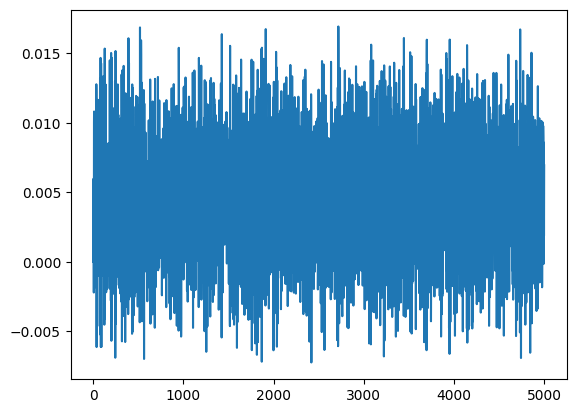

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

a1 = 0.6
a2 = -0.5
a3 = -0.2

n = 5000
np.random.seed(42)

U = np.random.uniform(0,0.01,5000)

X = np.zeros(n)

for i in range(3,n):
    X[i] = a1 * X[i-1] + a2 * X[i-2] + a3 * X[i-3] + U[i]
    
plt.plot(X)
plt.show

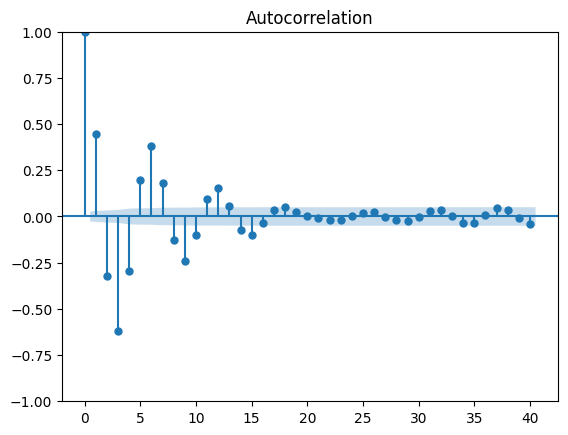

In [5]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(X, lags = 40)
plt.show()

C:\Users\geoma\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training size: 500, MSE Loss on test set: 0.016063977032899857
Training size: 2000, MSE Loss on test set: 0.014219890348613262
Training size: 4000, MSE Loss on test set: 0.015907375141978264
MSE loss on new dataset: 0.016330674290657043
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


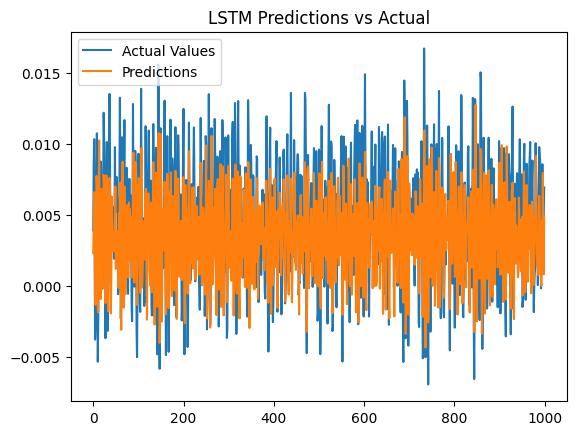

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Δημιουργία DataFrame για supervised learning

df = pd.DataFrame(X, columns=["X_t"])
df["X_t-1"] = df["X_t"].shift(1)
df["X_t-2"] = df["X_t"].shift(2)
df["X_t-3"] = df["X_t"].shift(3)
df.dropna(inplace=True)

# Διαχωρισμός σε training & testing set
train_size = int(0.8 * len(df))
X_train, X_test = df.iloc[:train_size, 1:].values, df.iloc[train_size:, 1:].values
y_train, y_test = df.iloc[:train_size, 0].values, df.iloc[train_size:, 0].values

# Κανονικοποίηση
scaler_X, scaler_y = MinMaxScaler(), MinMaxScaler()
X_train = scaler_X.fit_transform(X_train)
X_test = scaler_X.transform(X_test)
y_train = scaler_y.fit_transform(y_train.reshape(-1, 1))
y_test = scaler_y.transform(y_test.reshape(-1, 1))

# Reshape για LSTM
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# Κατασκευή RNN μοντέλου
model = Sequential([
    LSTM(25, activation="relu", input_shape=(3, 1)),
    Dense(1)
])
model.compile(optimizer="adam", loss="mse")

# Δοκιμή με διαφορετικά μεγέθη training set
sample_sizes = [500, 2000, 4000]
for size in sample_sizes:
    model.fit(X_train[:size], y_train[:size], epochs=15, batch_size=4, verbose=0)
    loss = model.evaluate(X_test, y_test, verbose=0)
    print(f"Training size: {size}, MSE Loss on test set: {loss}")

# Εκπαίδευση σε νέο σύνολο δεδομένων
np.random.seed(99)
U_new = np.random.uniform(0, 0.01, n)
X_new = np.zeros(n)
for i in range(3, n):
    X_new[i] = a1 * X_new[i-1] + a2 * X_new[i-2] + a3 * X_new[i-3] + U_new[i]

df_new = pd.DataFrame(X_new, columns=["X_t"])
df_new["X_t-1"] = df_new["X_t"].shift(1)
df_new["X_t-2"] = df_new["X_t"].shift(2)
df_new["X_t-3"] = df_new["X_t"].shift(3)
df_new.dropna(inplace=True)

X_new_train = scaler_X.transform(df_new.iloc[:, 1:].values)
y_new_train = scaler_y.transform(df_new.iloc[:, 0].values.reshape(-1, 1))
X_new_train = X_new_train.reshape(X_new_train.shape[0], X_new_train.shape[1], 1)

loss_new = model.evaluate(X_new_train, y_new_train, verbose=0)
print(f"MSE loss on new dataset: {loss_new}")

# Προβλέψεις και σύγκριση
predictions = model.predict(X_test)
predictions = scaler_y.inverse_transform(predictions)
y_test = scaler_y.inverse_transform(y_test)

plt.plot(y_test, label="Actual Values")
plt.plot(predictions, label="Predictions")
plt.legend()
plt.title("LSTM Predictions vs Actual")
plt.show()
